In [61]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV


In [62]:
df_audi = pd.read_csv('../datasets/audi.csv')
df_vw = pd.read_csv('../datasets/vw.csv')
df_skoda = pd.read_csv('../datasets/skoda.csv')


In [63]:
df_audi['brand'] = 'Audi'
df_vw['brand'] = 'VW'
df_skoda['brand'] = 'Skoda'

df = pd.concat([df_audi, df_vw, df_skoda], ignore_index=True) # merging the dataset
print(df.shape)
print(df.isnull().sum())

(32092, 10)
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
brand           0
dtype: int64


In [64]:
df = df.drop_duplicates().reset_index(drop=True) # removing duplicates
counts = df['model'].value_counts()
rare_models = counts[counts < 10].index

print(df.shape)

df = df[~df['model'].isin(rare_models)].reset_index(drop=True) # we drop the models whose frequency count < 10 

print(df.shape)


(31646, 10)
(31600, 10)


In [65]:
zero_engine = df[df['engineSize'] == 0] # some cars have engine size of 0 if they are not electric we should remove them
print(len(zero_engine))
print(zero_engine['fuelType'].value_counts())

bad_values = (df['engineSize'] == 0) & (df['fuelType'].isin(['Petrol', 'Diesel']))
df = df[~bad_values].reset_index(drop=True) # dropping the bad values


high_mpg = df[df['mpg'] > 150]
print(len(high_mpg))
bad_mpg = (df['mpg'] > 150) & (df['fuelType'].isin(['Other', 'Petrol', 'Diesel']))
df = df[~bad_mpg].reset_index(drop=True) # dropping bad mpg values

72
fuelType
Petrol    47
Diesel    25
Name: count, dtype: int64
121


In [66]:
X = df.drop('price', axis=1)
Y = df['price']

Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=42)
training_df = pd.concat([Xtrain, Ytrain], axis=1)
categorical_columns = ['brand', 'model', 'transmission', 'fuelType']

Xtrain = pd.get_dummies(Xtrain, columns=categorical_columns)
Xtest = pd.get_dummies(Xtest, columns=categorical_columns)

training_df_encoded = pd.concat([Xtrain, Ytrain] , axis=1)
Xtest = Xtest.reindex(columns=Xtrain.columns, fill_value=0) # training data has 2 extra columns so this line adds two extra columns in the test and puts their value to 0

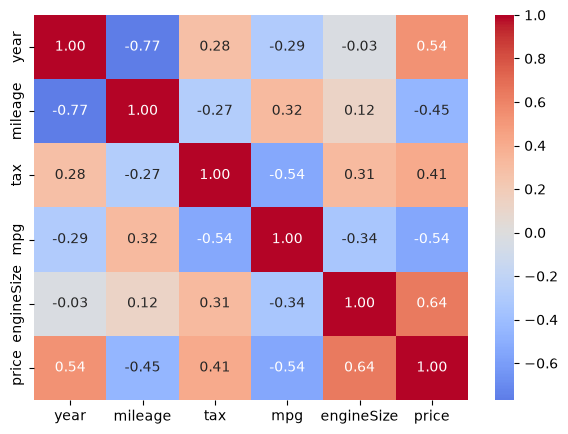

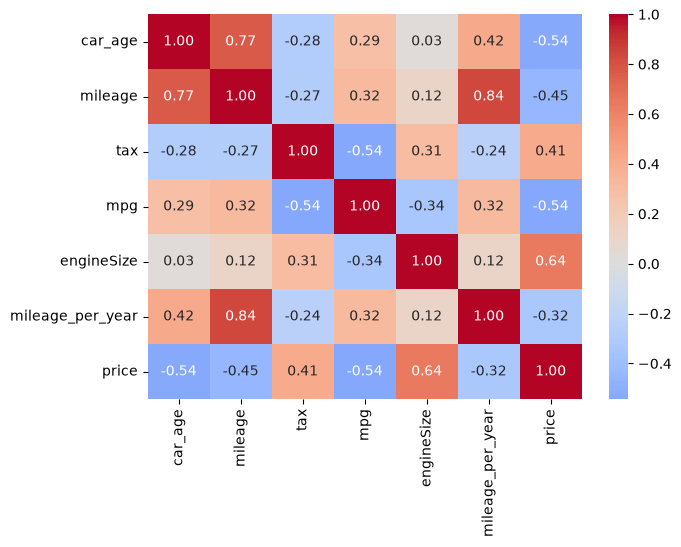

In [67]:
# correlation heatmaps for feature engineering 

num_cols = ['year', 'mileage', 'tax', 'mpg', 'engineSize', 'price']
plt.figure(figsize=(7, 5))
sns.heatmap(training_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

for d in (Xtrain, Xtest):
    d['car_age'] = 2020 - d['year']   
    d['mileage_per_year'] = d['mileage']/(d['car_age'] + 1)  
Xtrain = Xtrain.drop(columns=['year'])
Xtest = Xtest.drop(columns=['year'])

training_df2 = pd.concat([Xtrain, Ytrain], axis=1)
num_cols2 = ['car_age', 'mileage', 'tax', 'mpg', 'engineSize', 'mileage_per_year', 'price']
plt.figure(figsize=(7,5))
sns.heatmap(training_df2[num_cols2].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

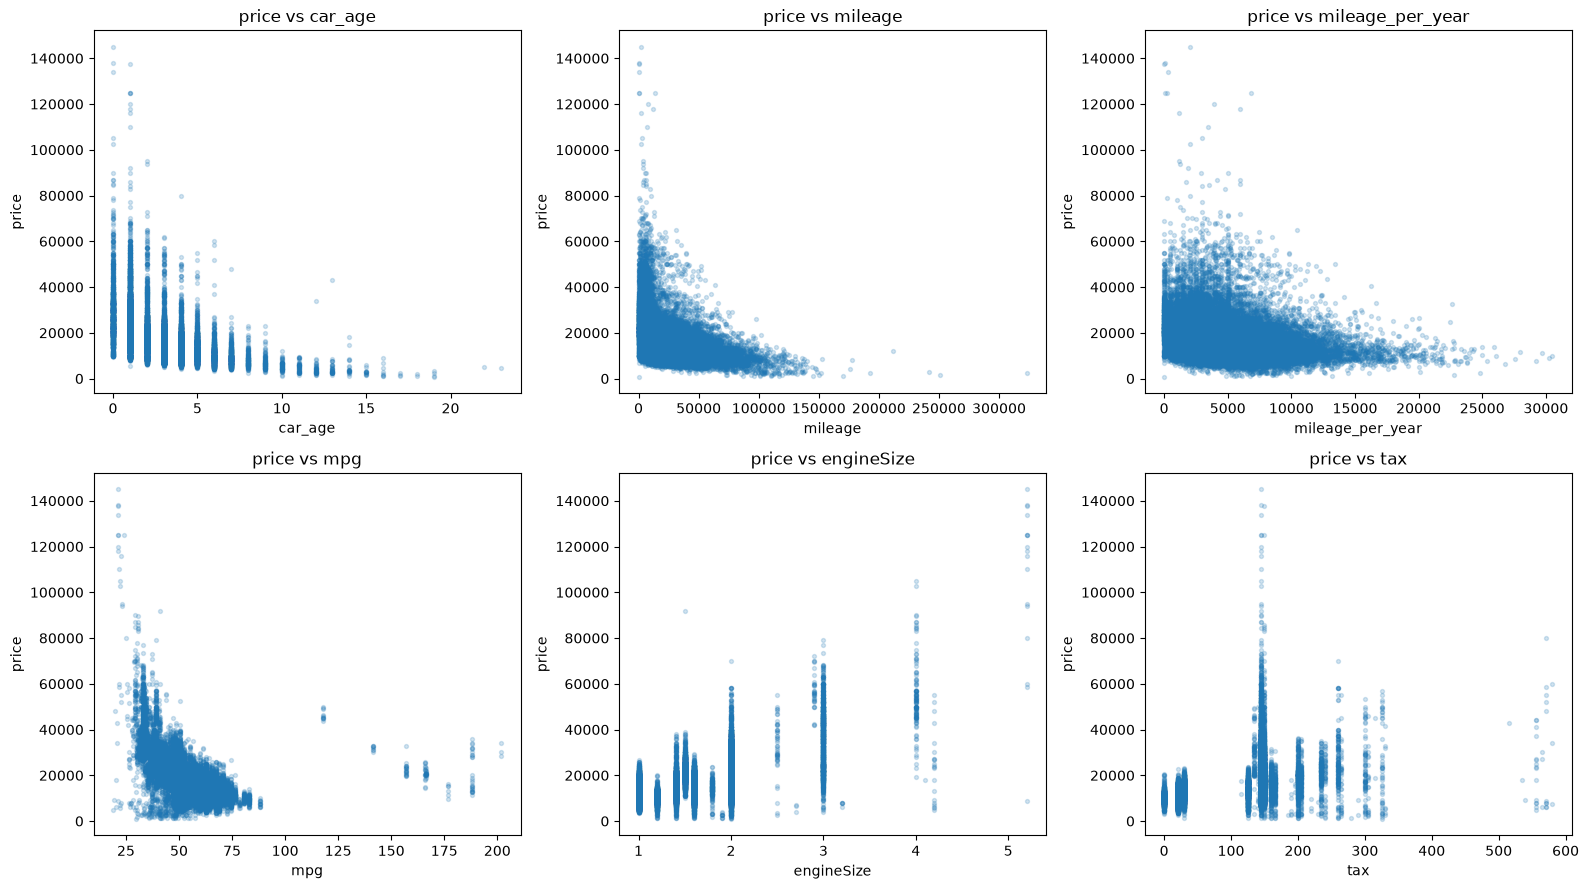

In [68]:
# plotting scatter plots for outlier detection 

features = ['car_age', 'mileage', 'mileage_per_year', 'mpg', 'engineSize', 'tax']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(training_df2[col], training_df2['price'], alpha=0.2, s=8)
    ax.set_xlabel(col)
    ax.set_ylabel('price')
    ax.set_title(f'price vs {col}')
plt.tight_layout()
plt.show()

In [69]:
print(Xtrain.shape, Xtest.shape)
print(Xtrain.isnull().sum().sum(), Xtest.isnull().sum().sum())   
print(list(Xtrain.columns) == list(Xtest.columns)) 
               
list1 = list(Xtrain.columns)
list2 = list(Xtest.columns)
print('Elements in list1 but not in list2', set(list1) - set(list2))
print('Elements in list2 but not in list1', set(list2) - set(list1))

Xtrain = Xtrain.astype(float)
Xtest = Xtest.astype(float)

(25214, 72) (6304, 72)
0 0
True
Elements in list1 but not in list2 set()
Elements in list2 but not in list1 set()


In [70]:
def evaluate(model, name):
    results = {}
    for label, X, y in [('train', Xtrain, Ytrain), ('test', Xtest, Ytest)]:
        pred = model.predict(X)
        results[label] = {
            'R2': r2_score(y, pred),
            'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
        }
    print(f"\n{name}")
    for label, m in results.items():
        print(f"  {label:5s}  R2={m['R2']:.3f}  MAE=£{m['MAE']:,.0f}  RMSE=£{m['RMSE']:,.0f}")
    return results

In [71]:
lr = LinearRegression()
lr.fit(Xtrain, Ytrain)
lr_results = evaluate(lr, 'LinearRegression')

rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(Xtrain, Ytrain)
rf_results = evaluate(rf, 'RandomForestRegressor')


LinearRegression
  train  R2=0.896  MAE=£2,050  RMSE=£3,092
  test   R2=0.891  MAE=£2,108  RMSE=£3,240

RandomForestRegressor
  train  R2=0.994  MAE=£464  RMSE=£738
  test   R2=0.961  MAE=£1,217  RMSE=£1,924


In [72]:
param_dist = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 15, 25, 35],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features': [1.0, 0.7, 0.5, 0.33],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_dist, n_iter=15, cv=3,
    scoring='neg_mean_absolute_error', random_state=42
)
search.fit(Xtrain, Ytrain)

print(search.best_params_)
tuned_rf = search.best_estimator_
tuned_results = evaluate(tuned_rf, 'Tuned RandomForest')

{'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 25}

Tuned RandomForest
  train  R2=0.987  MAE=£691  RMSE=£1,112
  test   R2=0.964  MAE=£1,187  RMSE=£1,848
